# Function 1 - Week 4: exploration

Review the measured outputs and input coverage in the independent Week 4 `observations.csv`,
including the confirmed Week 3 return received on 14 October 2026. Continue the saved coverage shortlist.

Descriptive plots and the observed-output terrain remain here. Fitted surfaces, uncertainty,
contours and target-treatment experiments are in [model predictions](model_predictions.ipynb).


In [16]:
# Imports & shared helpers
import numpy as np
import pandas as pd
from pathlib import Path
import sys

# Find Shared from any function/week folder inside notebooks.
shared_dir = next(
    (folder / "Shared"
     for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "plot_helpers.py").is_file()),
    None,
)
if shared_dir is None:
    raise FileNotFoundError(
        "Cannot find Shared/plot_helpers.py above the working directory. "
        "Run this notebook from within the notebooks folder."
    )
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from plot_helpers import (
    PLOT_CONFIG, plot_observed_terrain,
    plot_sampling_gaps, plot_fixed_exploration_progression,
)
from output_helpers import summarise_output_observations

# Function 1's helpers are shared across its weekly notebooks.
function_shared_dir = shared_dir.parent / "Function_1" / "FunctionSpecificShared"
if str(function_shared_dir) not in sys.path:
    sys.path.insert(0, str(function_shared_dir))

from function_1_plots import plot_output_number_line
from function_1_model_helpers import signed_log


In [17]:
# Data and output paths for this week's notebook.
# Start the kernel with this notebook's folder as its working directory.
week_dir = Path.cwd().resolve()
full_data_path = week_dir / "observations.csv"

if not (week_dir / "exploration.ipynb").is_file() or not full_data_path.is_file():
    raise FileNotFoundError(
        "Run this notebook with its own folder as the working directory; "
        "exploration.ipynb and observations.csv must be together."
    )

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)



In [18]:
# Basic data load
print(f"Loading data from: {full_data_path}")
data = pd.read_csv(full_data_path, float_precision="round_trip")

Loading data from: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\notebooks\Function_1\Week_04\observations.csv


In [19]:
# Column inspection
columns = data.columns
print("Columns: ", columns)

Columns:  Index(['observation_id', 'source_round', 'x1', 'x2', 'y'], dtype='str')


In [20]:
# Where we pray for good data, aka checking for nulls
print (data.isna().sum())

observation_id    0
source_round      0
x1                0
x2                0
y                 0
dtype: int64


In [21]:
# Prepare observation labels for the exploration plots
plot_data = data.copy()
plot_data["rank"] = (
    plot_data["y"]
    .rank(ascending=False, method="min")
    .astype(int)
)

In [22]:
# Splitting our data into inputs X and outputs y
output_column = "y"
input_columns = ["x1", "x2"]

#print("Input columns: ", input_columns)
#print("Output column: ", output_column)

X = data[input_columns]
y = data[output_column]

#print("The inputs are given by :")
#print(X.head())
#print("The outputs are given by :")
#print(y[:5])


In [23]:
# So now we have:

# data	       = Observations as loaded from the CSV
# X, y	       = Inputs and outputs selected from those observations
# plot_data	   = A separate copy enriched for the exploration plots

In [24]:
# Review the latest recorded submission against earlier observed outputs.
output_review = summarise_output_observations(
    data,
    input_columns=input_columns,
    output_column=output_column,
)
print(output_review["report"])


Latest recorded submission: round 3 (1 new output).
Compared with 12 earlier observations (13 outputs in total).
Earlier output range: [-0.00550934555381, 7.7108751145e-16].

round-03: y = 1.97281177559e-200 (positive); rank 8/13 (1 = highest output).
Inputs: x1 = 0.781859, x2 = 0.025607
Within the earlier output range. Smallest non-zero magnitude so far (76.2 orders below the earlier smallest).


## Observed outputs

The number line summarises the measured **outputs**: negatives on the left and positives on the right,
with matching logarithmic magnitude scales. Better signed outputs run from left to right.
The centre is a **virtual zero**, a divider between the log axes; actual zeros, if present, sit in the centre.

The latest result is starred and labelled with its signed value and rank among all observations.
Input-space coverage is examined separately in the sampling-gap plots below.


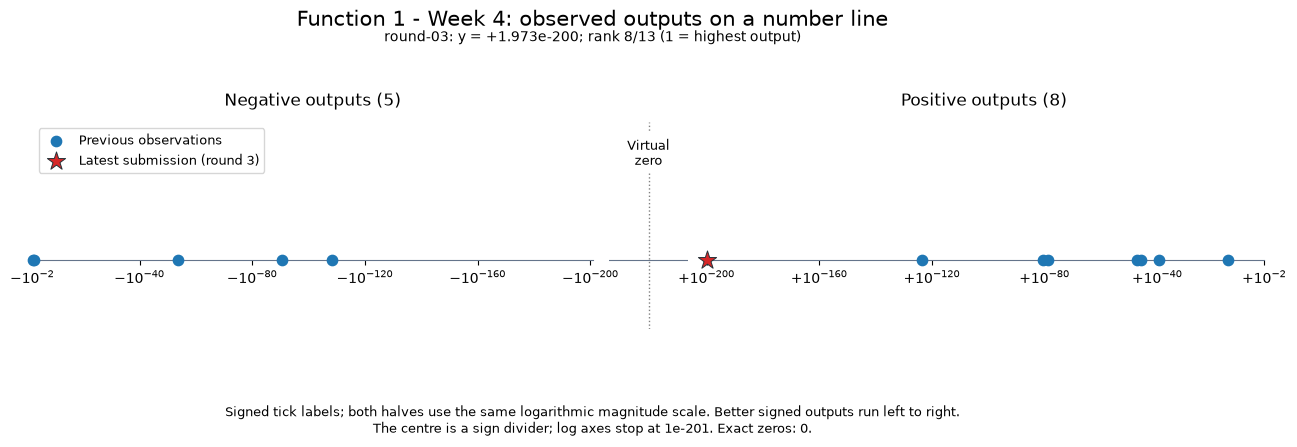

In [25]:
plot_output_number_line(
    output_review,
    title="Function 1 - Week 4: observed outputs on a number line",
    save_to=figures / "output-number-line.png",
)

## Observed ranks and sampling gaps

Circle numbers are observed output ranks (1 = highest). The background shows distance to the nearest observed point.


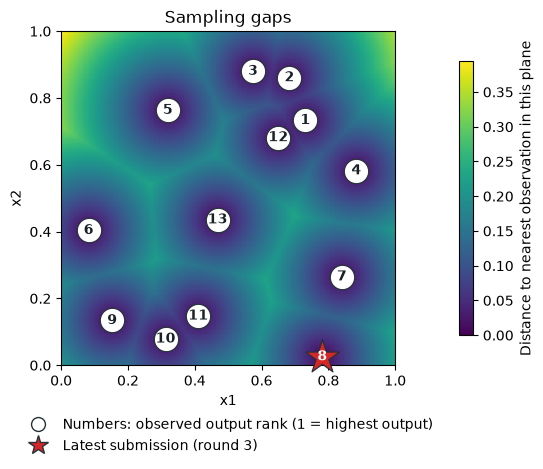

In [26]:
# Visualisation of the input-space coverage of the observations so far.
sampling_gaps_fig = plot_sampling_gaps(
    plot_data, highlight=output_review["latest_mask"],
    highlight_label=f"Latest submission (round {output_review['latest_round']})",
)
sampling_gaps_fig.set_size_inches(sampling_gaps_fig.get_size_inches() * 0.75)
sampling_gaps_fig.savefig(figures / "sampling-gaps.png", dpi=160)
sampling_gaps_fig


## Observed-output terrain

The signed-log height makes the enormous output range visible while preserving signs and order.
Black markers are measurements; the gold diamond identifies the highest observed output.
The triangular faces simply join measured heights. They are a visual interpolation, not a fitted regression or a known function surface.
Blank areas lie outside the sampled region. Drag to rotate, scroll to zoom, and use **Reset view** to restore the initial orientation and zoom.


In [27]:
# Observed outputs as a draggable terrain; the display scale is Function 1-specific.
terrain_y = y.to_numpy(dtype=float)
nonzero_magnitudes = np.abs(terrain_y[terrain_y != 0])
terrain_scale = 10.0 ** np.floor(np.log10(nonzero_magnitudes.min()))
terrain_ticks = [-1e-3, 0, 1e-15]
terrain_html = figures / "observed-output-terrain.html"
terrain_fig = plot_observed_terrain(
    X.to_numpy(), terrain_y,
    title=f"Function 1: observed-output terrain ({len(terrain_y)} samples)",
    heights=signed_log(terrain_y, scale=terrain_scale),
    height_axis=dict(title="Output y (signed log)", tickmode="array",
                     tickvals=signed_log(terrain_ticks, scale=terrain_scale),
                     ticktext=[f"{value:.0e}" if value else "0" for value in terrain_ticks]),
    height_description="signed-log heights", relief=0.16, save_to=terrain_html,
    width=850, height=560, camera=dict(eye=dict(x=-1.05, y=-1.35, z=0.9)),
    show_reset=True,
)
print(f"Height = sign(y) * log10(1 + |y| / {terrain_scale:.0e}); tick labels show original y.")
print(f"Interactive browser copy: {terrain_html}")
terrain_fig.show(config={**PLOT_CONFIG, "responsive": False})


Height = sign(y) * log10(1 + |y| / 1e-200); tick labels show original y.
Interactive browser copy: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\notebooks\Function_1\Week_04\figures\observed-output-terrain.html


## Next query(s)

In [28]:
# Fixed Week 2 plan, preserved at full precision; no optimisation is run.
planned_queries = pd.DataFrame(
    [[0.15308205385104573, 0.13395525138390008], [0.7818589422435338, 0.0256071460565101], [0.12954929624948736, 0.822189245547224], [0.9121401448788213, 0.8617829948823881]],
    columns=input_columns,
)

# The saved sequence starts in Week 2; keep only this week's unevaluated remainder.
current_week = int(week_dir.name.removeprefix("Week_"))
coverage_queries = planned_queries.iloc[current_week - 2:].copy()


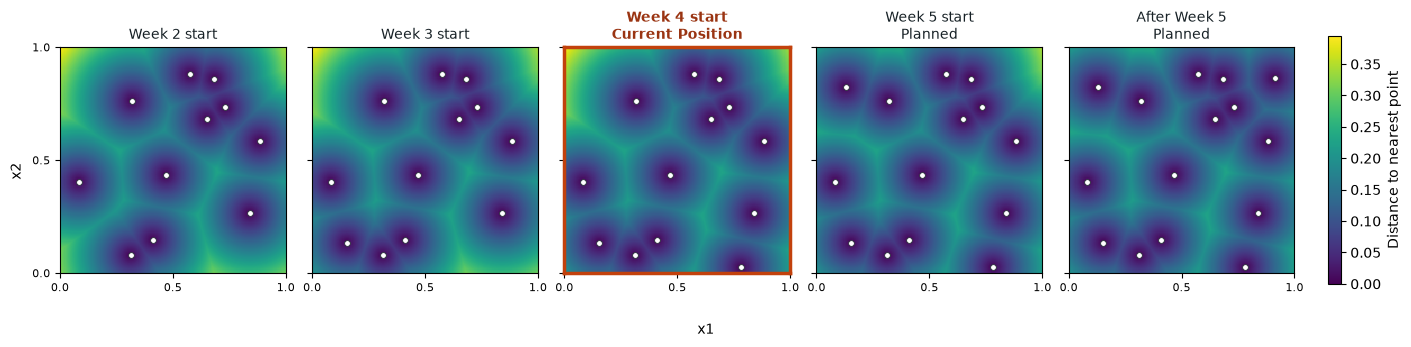

In [29]:
plot_fixed_exploration_progression(
    data, planned_queries,
    current_week=current_week,
    save_to=figures / "fixed-exploration-progression.png",
)

In [30]:
# Copy the portal-ready input from the row for the required week.
remaining_queries = coverage_queries.copy()
remaining_queries.index = pd.Index(
    range(current_week, current_week + len(remaining_queries)), name="Week",
)
remaining_queries["Portal input"] = [
    "-".join(f"{value:.6f}" for value in point)
    for point in coverage_queries.to_numpy()
]
remaining_queries.style.format({column: "{:.6f}" for column in input_columns})

,x1,x2,Portal input
Week,,,
4,0.129549,0.822189,0.129549-0.822189
5,0.912140,0.861783,0.912140-0.861783


## Continue with model predictions (for fun)

This optional continuation is for learning and experimentation. Week 4 and the remaining
pure exploration queries follow the fixed exploration plan above.

[Model predictions](model_predictions.ipynb) includes the fitted quadratics, contour comparisons,
negative-to-zero experiment, model validation and GP uncertainty plots. It loads this week's
observations independently.
